# Semana 4 Interfaces composición e inyección de dependencias

Definir contratos intercambiables para notificaciones y reportes, y separar la cotización del hotel mediante una dependencia recibida desde el exterior.

Identificador S4-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


class Reserva:
    def __init__(self, codigo, entrada, salida):
        self.__codigo = texto(codigo)
        self.__entrada = date.fromisoformat(entrada)
        self.__salida = date.fromisoformat(salida)
        if self.__salida <= self.__entrada:
            raise ValueError("Salida debe ser posterior")
        self.__estado = "REGISTRADA"

    @property
    def codigo(self):
        return self.__codigo

    @property
    def entrada(self):
        return self.__entrada.isoformat()

    @property
    def salida(self):
        return self.__salida.isoformat()

    @property
    def noches(self):
        return (self.__salida - self.__entrada).days

    @property
    def estado(self):
        return self.__estado

    def confirmar(self):
        if self.estado != "REGISTRADA":
            raise RuntimeError("Confirmacion no permitida")
        self.__estado = "CONFIRMADA"

    def anular(self):
        if self.estado == "ANULADA":
            raise RuntimeError("Reserva ya anulada")
        self.__estado = "ANULADA"


### python\hotel_herencia.py

In [ ]:
%%writefile python/hotel_herencia.py
"""Semana 3: las categorías son habitaciones y conservan el contrato de precio."""

from .hotel_base import Habitacion


class HabitacionSimple(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Simple", 1, tarifa)

    def precio_noche(self):
        return self.tarifa


class HabitacionDoble(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Doble", 2, tarifa)

    def precio_noche(self):
        return self.tarifa * 1.5


class Suite(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Suite", 4, tarifa)

    def precio_noche(self):
        return self.tarifa * 2


def cotizar_habitaciones(habitaciones):
    return [h.precio_noche() for h in habitaciones]


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
"""Notificaciones simuladas y reportes intercambiables mediante contratos."""

from abc import ABC, abstractmethod
from typing import Protocol, runtime_checkable
from pathlib import Path
import csv
import io
import json


class INotificador(ABC):
    @abstractmethod
    def enviar(self, destinatario, mensaje):
        raise NotImplementedError

    @abstractmethod
    def es_disponible(self):
        raise NotImplementedError

    @property
    @abstractmethod
    def nombre(self):
        raise NotImplementedError


@runtime_checkable
class ProtocolNotificador(Protocol):
    def enviar(self, destinatario: str, mensaje: str) -> bool: ...
    def es_disponible(self) -> bool: ...


class CanalSimulado:
    """Comportamiento compartido por composición, sin envío real."""

    def __init__(self, servidor):
        if not servidor.strip():
            raise ValueError("Servidor vacio")
        self._servidor, self.activo, self.enviados = servidor, True, []

    def es_disponible(self):
        return self.activo

    def enviar(self, destinatario, mensaje):
        if not self.es_disponible():
            return False
        if not destinatario.strip() or not mensaje:
            raise ValueError("Destino o mensaje vacio")
        self.enviados.append((destinatario, mensaje))
        return True


class NotificadorEmail(INotificador):
    def __init__(self, servidor):
        self._canal = CanalSimulado(servidor)

    @property
    def nombre(self):
        return "Email"

    @property
    def enviados(self):
        return self._canal.enviados

    @property
    def activo(self):
        return self._canal.activo

    @activo.setter
    def activo(self, valor):
        self._canal.activo = valor

    def es_disponible(self):
        return self._canal.es_disponible()

    def enviar(self, destinatario, mensaje):
        return self._canal.enviar(destinatario, mensaje)


class NotificadorSMS(INotificador):
    MAX_CHARS = 160

    def __init__(self, proveedor):
        self._canal = CanalSimulado(proveedor)

    @property
    def nombre(self):
        return "SMS"

    def es_disponible(self):
        return self._canal.es_disponible()

    def enviar(self, destinatario, mensaje):
        if len(mensaje) > self.MAX_CHARS:
            raise ValueError("SMS excede 160 caracteres")
        return self._canal.enviar(destinatario, mensaje)


class SistemaAlertas:
    def __init__(self, notificadores):
        if not notificadores:
            raise ValueError("Se requiere un canal")
        self._notificadores = list(notificadores)
        self.errores = []

    def agregar_notificador(self, notificador):
        self._notificadores.append(notificador)

    def alertar(self, dest, mensaje):
        enviados = 0
        for notificador in self._notificadores:
            try:
                if notificador.es_disponible() and notificador.enviar(dest, mensaje):
                    enviados += 1
            except Exception as error:
                self.errores.append(str(error))
        return enviados


class Exportador(ABC):
    @property
    @abstractmethod
    def extension(self):
        raise NotImplementedError

    @abstractmethod
    def exportar(self, contenido, ruta):
        raise NotImplementedError


class ExportadorCSV(Exportador):
    @property
    def extension(self):
        return ".csv"

    def exportar(self, contenido, ruta):
        datos = json.loads(contenido)
        salida = io.StringIO(newline="")
        escritor = csv.writer(salida, lineterminator="\n")
        escritor.writerow(datos.keys())
        escritor.writerow(datos.values())
        Path(str(ruta) + self.extension).write_text(salida.getvalue(), encoding="utf-8")


class ExportadorJSON(Exportador):
    @property
    def extension(self):
        return ".json"

    def exportar(self, contenido, ruta):
        json.loads(contenido)
        Path(str(ruta) + self.extension).write_text(contenido, encoding="utf-8")


class Firmador(ABC):
    @abstractmethod
    def firmar(self, ruta):
        raise NotImplementedError


class FirmadorDigital(Firmador):
    """Simulación didáctica; no representa una firma criptográfica válida."""

    def firmar(self, ruta):
        destino = str(ruta) + ".signed"
        Path(destino).write_text(
            "FIRMA SIMULADA\n" + Path(ruta).read_text(encoding="utf-8"), encoding="utf-8"
        )
        return destino


class GeneradorReporte:
    def __init__(self, exportador, firmador=None):
        self._exportador, self._firmador = exportador, firmador

    def cambiar_exportador(self, exportador):
        self._exportador = exportador

    def generar(self, datos, ruta):
        contenido = json.dumps(datos, ensure_ascii=False, allow_nan=False)
        self._exportador.exportar(contenido, ruta)
        destino = str(ruta) + self._exportador.extension
        return self._firmador.firmar(destino) if self._firmador else destino


class CalculadoraTarifa(ABC):
    @abstractmethod
    def calcular(self, habitacion, noches):
        raise NotImplementedError

    @abstractmethod
    def descripcion(self):
        raise NotImplementedError


class TarifaEstandar(CalculadoraTarifa):
    def calcular(self, habitacion, noches):
        if type(noches) is not int or noches < 1:
            raise ValueError("Noches positivas requeridas")
        return habitacion.precio_noche() * noches

    def descripcion(self):
        return "Estandar"


class ServicioCotizacion:
    def __init__(self, calculadora):
        self._calculadora = calculadora

    def cotizar(self, habitacion, noches):
        return self._calculadora.calcular(habitacion, noches)


def demo():
    from .hotel_herencia import HabitacionDoble

    email, sms = NotificadorEmail("smtp.local"), NotificadorSMS("Simulado")
    alertas = SistemaAlertas([email, sms])
    return [
        f"CANALES={alertas.alertar('destino_prueba','Aviso de prueba')}",
        f"SMS_LARGO={alertas.alertar('destino_prueba','X'*161)}",
        f"COTIZACION={ServicioCotizacion(TarifaEstandar()).cotizar(HabitacionDoble(102),2):.2f}",
    ]


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};

class Reserva {
    std::string codigo_, entrada_, salida_, estado_ = "REGISTRADA";

  public:
    Reserva(std::string codigo, std::string entrada, std::string salida)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)) {
        textoValido(codigo_);
        if (ordinal(salida_) <= ordinal(entrada_)) {
            throw std::invalid_argument("Salida debe ser posterior");
        }
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::string &estado() const noexcept {
        return estado_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    void confirmar() {
        if (estado_ != "REGISTRADA") {
            throw std::runtime_error("Confirmacion no permitida");
        }
        estado_ = "CONFIRMADA";
    }
    void anular() {
        if (estado_ == "ANULADA") {
            throw std::runtime_error("Reserva ya anulada");
        }
        estado_ = "ANULADA";
    }
};


### cpp\hotel_herencia.hpp

In [ ]:
%%writefile cpp/hotel_herencia.hpp
#pragma once
#include "hotel_base.hpp"
class HabitacionSimple : public Habitacion {
  public:
    explicit HabitacionSimple(int numero, double tarifa = 100)
        : Habitacion(numero, "Simple", 1, tarifa) {}
    double precioNoche() const override {
        return tarifa();
    }
};
class HabitacionDoble : public Habitacion {
  public:
    explicit HabitacionDoble(int numero, double tarifa = 100)
        : Habitacion(numero, "Doble", 2, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 1.5;
    }
};
class Suite : public Habitacion {
  public:
    explicit Suite(int numero, double tarifa = 100) : Habitacion(numero, "Suite", 4, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 2;
    }
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include <cstdio>
#include "solucion.hpp"
#include <type_traits>
class ExportadorMock : public Exportador {
  public:
    mutable int llamadas = 0;
    std::string extension() const override {
        return ".mock";
    }
    void exportar(const std::string &, const std::string &) const override {
        ++llamadas;
    }
};
std::vector<std::unique_ptr<INotificador>> canales() {
    std::vector<std::unique_ptr<INotificador>> ns;
    ns.push_back(std::make_unique<NotificadorEmail>("local"));
    ns.push_back(std::make_unique<NotificadorSMS>("local"));
    return ns;
}
int main() {
    Pruebas t;
    t.caso("interfaz abstracta", [] { exigir(std::is_abstract<INotificador>::value); });
    t.caso("dos canales", [] {
        SistemaAlertas s(canales());
        exigir(s.alertar("d", "mensaje") == 2);
    });
    t.caso("indisponible", [] {
        auto ns = canales();
        static_cast<NotificadorEmail *>(ns[0].get())->setActivo(false);
        SistemaAlertas s(std::move(ns));
        exigir(s.alertar("d", "mensaje") == 1);
    });
    t.caso("sms limites", [] {
        NotificadorSMS n("local");
        exigir(n.enviar("d", std::string(160, 'x')));
        debeFallar([&] { n.enviar("d", std::string(161, 'x')); });
    });
    t.caso("errores aislados", [] {
        SistemaAlertas s(canales());
        exigir(s.alertar("d", std::string(161, 'x')) == 1 && s.errores.size() == 1);
    });
    t.caso("vacio", [] { debeFallar([] { SistemaAlertas s({}); }); });
    t.caso("mock", [] {
        auto mock = std::make_unique<ExportadorMock>();
        auto *vista = mock.get();
        GeneradorReporte g(std::move(mock));
        exigir(g.generar("datos", "prueba") == "prueba.mock");
        exigir(vista->llamadas == 1);
    });
    t.caso("exportacion y firma", [] {
        GeneradorReporte g(std::make_unique<ExportadorCSV>(), std::make_unique<FirmadorDigital>());
        exigir(g.generar("n\n45\n", "reporte_prueba_exportacion") == "reporte_prueba_exportacion.csv.signed");
        g.cambiarExportador(std::make_unique<ExportadorJSON>());
        exigir(g.generar("{\"n\":45}", "reporte_prueba_exportacion") == "reporte_prueba_exportacion.json.signed");
        for (const auto *extension : {".csv", ".csv.signed", ".json", ".json.signed"}) {
            std::remove((std::string("reporte_prueba_exportacion") + extension).c_str());
        }
    });
    t.caso("inyeccion hotel", [] {
        ServicioCotizacion s(std::make_unique<TarifaEstandar>());
        exigir(s.cotizar(HabitacionDoble(102), 2) == 300);
    });
    t.caso("noches invalidas", [] {
        ServicioCotizacion s(std::make_unique<TarifaEstandar>());
        debeFallar([&] { s.cotizar(HabitacionDoble(102), 0); });
    });
    return t.terminar();
}


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "comun.hpp"
#include "hotel_herencia.hpp"
#include <fstream>

class INotificador {
  public:
    virtual ~INotificador() = default;
    virtual bool enviar(const std::string &, const std::string &) = 0;
    virtual bool esDisponible() const = 0;
    virtual std::string nombre() const = 0;
};
class CanalSimulado {
    std::string servidor_;
    bool activo_ = true;

  public:
    std::vector<std::pair<std::string, std::string>> enviados;
    explicit CanalSimulado(std::string servidor) : servidor_(std::move(servidor)) {
        textoValido(servidor_);
    }
    bool esDisponible() const {
        return activo_;
    }
    void setActivo(bool v) {
        activo_ = v;
    }
    bool enviar(const std::string &dest, const std::string &mensaje) {
        if (!esDisponible()) {
            return false;
        }
        textoValido(dest);
        textoValido(mensaje);
        enviados.push_back({dest, mensaje});
        return true;
    }
};
class NotificadorEmail : public INotificador {
    CanalSimulado canal_;

  public:
    explicit NotificadorEmail(std::string origen) : canal_(std::move(origen)) {}
    std::string nombre() const override {
        return "Email";
    }
    bool esDisponible() const override {
        return canal_.esDisponible();
    }
    void setActivo(bool v) {
        canal_.setActivo(v);
    }
    bool enviar(const std::string &d, const std::string &m) override {
        return canal_.enviar(d, m);
    }
};
inline std::size_t caracteresUTF8(const std::string &texto) {
    std::size_t total = 0;
    for (unsigned char c : texto) {
        if ((c & 0xc0) != 0x80) {
            ++total;
        }
    }
    return total;
}
class NotificadorSMS : public INotificador {
    CanalSimulado canal_;

  public:
    explicit NotificadorSMS(std::string origen) : canal_(std::move(origen)) {}
    bool esDisponible() const override {
        return canal_.esDisponible();
    }
    std::string nombre() const override {
        return "SMS";
    }
    bool enviar(const std::string &destino, const std::string &mensaje) override {
        if (caracteresUTF8(mensaje) > 160) {
            throw std::invalid_argument("SMS largo");
        }
        return canal_.enviar(destino, mensaje);
    }
};
class SistemaAlertas {
    std::vector<std::unique_ptr<INotificador>> notificadores_;

  public:
    std::vector<std::string> errores;
    explicit SistemaAlertas(std::vector<std::unique_ptr<INotificador>> ns)
        : notificadores_(std::move(ns)) {
        if (notificadores_.empty()) {
            throw std::invalid_argument("Se requiere un canal");
        }
        for (const auto &n : notificadores_) {
            if (!n) {
                throw std::invalid_argument("Canal nulo");
            }
        }
    }
    int alertar(const std::string &dest, const std::string &mensaje) {
        int total = 0;
        for (auto &n : notificadores_) {
            try {
                if (n->esDisponible() && n->enviar(dest, mensaje)) {
                    ++total;
                }
            } catch (const std::exception &e) {
                errores.push_back(e.what());
            }
        }
        return total;
    }
};
inline void escribir(const std::string &ruta, const std::string &contenido) {
    std::ofstream f(ruta);
    if (!f) {
        throw std::runtime_error("No se pudo abrir reporte");
    }
    f << contenido;
    if (!f) {
        throw std::runtime_error("No se pudo escribir reporte");
    }
}
class Exportador {
  public:
    virtual ~Exportador() = default;
    virtual std::string extension() const = 0;
    virtual void exportar(const std::string &contenido, const std::string &ruta) const = 0;
};
class ExportadorCSV : public Exportador {
  public:
    std::string extension() const override {
        return ".csv";
    }
    void exportar(const std::string &contenido, const std::string &ruta) const override {
        escribir(ruta + extension(), contenido);
    }
};
class ExportadorJSON : public Exportador {
  public:
    std::string extension() const override {
        return ".json";
    }
    void exportar(const std::string &contenido, const std::string &ruta) const override {
        escribir(ruta + extension(), contenido);
    }
};
class Firmador {
  public:
    virtual ~Firmador() = default;
    virtual std::string firmar(const std::string &ruta) const = 0;
};
class FirmadorDigital : public Firmador {
  public:
    std::string firmar(const std::string &ruta) const override {
        std::ifstream f(ruta);
        if (!f) {
            throw std::runtime_error("Reporte inexistente");
        }
        std::ostringstream contenido;
        contenido << f.rdbuf();
        escribir(ruta + ".signed", "FIRMA SIMULADA\n" + contenido.str());
        return ruta + ".signed";
    }
};
class GeneradorReporte {
    std::unique_ptr<Exportador> exportador_;
    std::unique_ptr<Firmador> firmador_;

  public:
    explicit GeneradorReporte(std::unique_ptr<Exportador> exp,
                              std::unique_ptr<Firmador> firma = nullptr)
        : exportador_(std::move(exp)), firmador_(std::move(firma)) {
        if (!exportador_) {
            throw std::invalid_argument("Exportador nulo");
        }
    }
    void cambiarExportador(std::unique_ptr<Exportador> exp) {
        if (!exp) {
            throw std::invalid_argument("Exportador nulo");
        }
        exportador_ = std::move(exp);
    }
    std::string generar(const std::string &contenido, const std::string &ruta) const {
        exportador_->exportar(contenido, ruta);
        auto salida = ruta + exportador_->extension();
        return firmador_ ? firmador_->firmar(salida) : salida;
    }
};
class CalculadoraTarifa {
  public:
    virtual ~CalculadoraTarifa() = default;
    virtual double calcular(const Habitacion &, int noches) const = 0;
    virtual std::string descripcion() const = 0;
};
class TarifaEstandar : public CalculadoraTarifa {
  public:
    double calcular(const Habitacion &h, int noches) const override {
        if (noches < 1) {
            throw std::invalid_argument("Noches invalidas");
        }
        return h.precioNoche() * noches;
    }
    std::string descripcion() const override {
        return "Estandar";
    }
};
class ServicioCotizacion {
    std::unique_ptr<CalculadoraTarifa> calculadora_;

  public:
    explicit ServicioCotizacion(std::unique_ptr<CalculadoraTarifa> c) : calculadora_(std::move(c)) {
        if (!calculadora_) {
            throw std::invalid_argument("Calculadora nula");
        }
    }
    double cotizar(const Habitacion &h, int noches) const {
        return calculadora_->calcular(h, noches);
    }
};
inline void demo() {
    std::vector<std::unique_ptr<INotificador>> ns;
    ns.push_back(std::make_unique<NotificadorEmail>("smtp.local"));
    ns.push_back(std::make_unique<NotificadorSMS>("Simulado"));
    SistemaAlertas alertas(std::move(ns));
    ServicioCotizacion servicio(std::make_unique<TarifaEstandar>());
    std::cout << "CANALES=" << alertas.alertar("destino_prueba", "Aviso de prueba")
              << "\nSMS_LARGO=" << alertas.alertar("destino_prueba", std::string(161, 'X'))
              << "\nCOTIZACION=" << std::fixed << std::setprecision(2)
              << servicio.cotizar(HabitacionDoble(102), 2) << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
import tempfile
import json
from pathlib import Path
from python.solucion import *
from python.hotel_herencia import HabitacionDoble


class ExportadorMock(Exportador):
    def __init__(self):
        self.llamadas = []

    @property
    def extension(self):
        return ".mock"

    def exportar(self, contenido, ruta):
        self.llamadas.append((contenido, ruta))


class ContratosSemana4(unittest.TestCase):
    def test_abc_no_instanciable(self):
        with self.assertRaises(TypeError):
            INotificador()

    def test_protocol_estructural(self):
        class Canal:
            def enviar(self, d, m):
                return True

            def es_disponible(self):
                return True

        self.assertIsInstance(Canal(), ProtocolNotificador)

    def test_dos_canales(self):
        self.assertEqual(
            SistemaAlertas([NotificadorEmail("local"), NotificadorSMS("local")]).alertar(
                "d", "mensaje"
            ),
            2,
        )

    def test_canal_no_disponible(self):
        n = NotificadorEmail("local")
        n.activo = False
        self.assertEqual(SistemaAlertas([n, NotificadorSMS("local")]).alertar("d", "mensaje"), 1)

    def test_sms_limites(self):
        n = NotificadorSMS("local")
        self.assertTrue(n.enviar("d", "á" * 160))
        with self.assertRaises(ValueError):
            n.enviar("d", "x" * 161)

    def test_error_aislado_no_detiene_otros(self):
        s = SistemaAlertas([NotificadorSMS("local"), NotificadorEmail("local")])
        self.assertEqual(s.alertar("d", "X" * 161), 1)
        self.assertEqual(len(s.errores), 1)

    def test_lista_vacia(self):
        with self.assertRaises(ValueError):
            SistemaAlertas([])

    def test_mock_sin_archivos(self):
        mock = ExportadorMock()
        GeneradorReporte(mock).generar({"n": 45}, "prueba")
        self.assertEqual(len(mock.llamadas), 1)
        self.assertEqual(json.loads(mock.llamadas[0][0]), {"n": 45})

    def test_cambio_exportador_y_firma(self):
        with tempfile.TemporaryDirectory() as d:
            base = Path(d) / "reporte"
            g = GeneradorReporte(ExportadorCSV())
            self.assertTrue(Path(g.generar({"n": 45}, base)).is_file())
            g.cambiar_exportador(ExportadorJSON())
            self.assertEqual(
                json.loads(Path(g.generar({"n": 45}, base)).read_text(encoding="utf-8")), {"n": 45}
            )
            firmado = GeneradorReporte(ExportadorCSV(), FirmadorDigital()).generar({"n": 45}, base)
            self.assertIn("FIRMA SIMULADA", Path(firmado).read_text(encoding="utf-8"))

    def test_inyeccion_hotel(self):
        self.assertEqual(ServicioCotizacion(TarifaEstandar()).cotizar(HabitacionDoble(102), 2), 300)

    def test_noches_invalidas(self):
        with self.assertRaises(ValueError):
            ServicioCotizacion(TarifaEstandar()).cotizar(HabitacionDoble(102), 0)


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


CANALES=2
SMS_LARGO=1
COTIZACION=300.00


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Análisis y reflexión

### Agregar XML
En composición basta un nuevo ExportadorXML; las combinaciones con y sin firma reutilizan el generador. En el diseño concreto de herencia pueden requerirse variantes para las combinaciones. El número depende de esa jerarquía, no hay una cifra universal.

### Mock para GeneradorReporte
Debe implementar extension y exportar, registrar contenido y ruta y no tocar el sistema de archivos. La prueba compara el número de llamadas y los datos recibidos.

### CSV con firma y JSON sin firma
Se construyen dos generadores con dependencias diferentes, o se cambia el exportador de uno. Las configuraciones conviven sin introducir una subclase por combinación.

### Protocol frente a ABC
Protocol admite conformidad estructural sin modificar clases ajenas. ABC conviene cuando se necesita impedir instanciaciones incompletas o compartir un contrato nominal. runtime_checkable comprueba presencia de miembros, no la corrección completa de sus tipos o de su conducta.

### Dependencias creadas internamente
Un cliente que construye su base de datos fuerza conexiones o recursos durante una prueba. Recibir la abstracción permite sustituirla por memoria y verificar la coordinación sin infraestructura real.

### Herencia múltiple
Puede introducir ambigüedad, duplicación de bases y conflicto de inicialización. Python dispone de MRO y super cooperativo; C++ ofrece reglas propias y herencia virtual. Java no permite herencia múltiple de clases concretas. Ninguno de estos hechos obliga a usar jerarquías profundas.

## diagrama clases

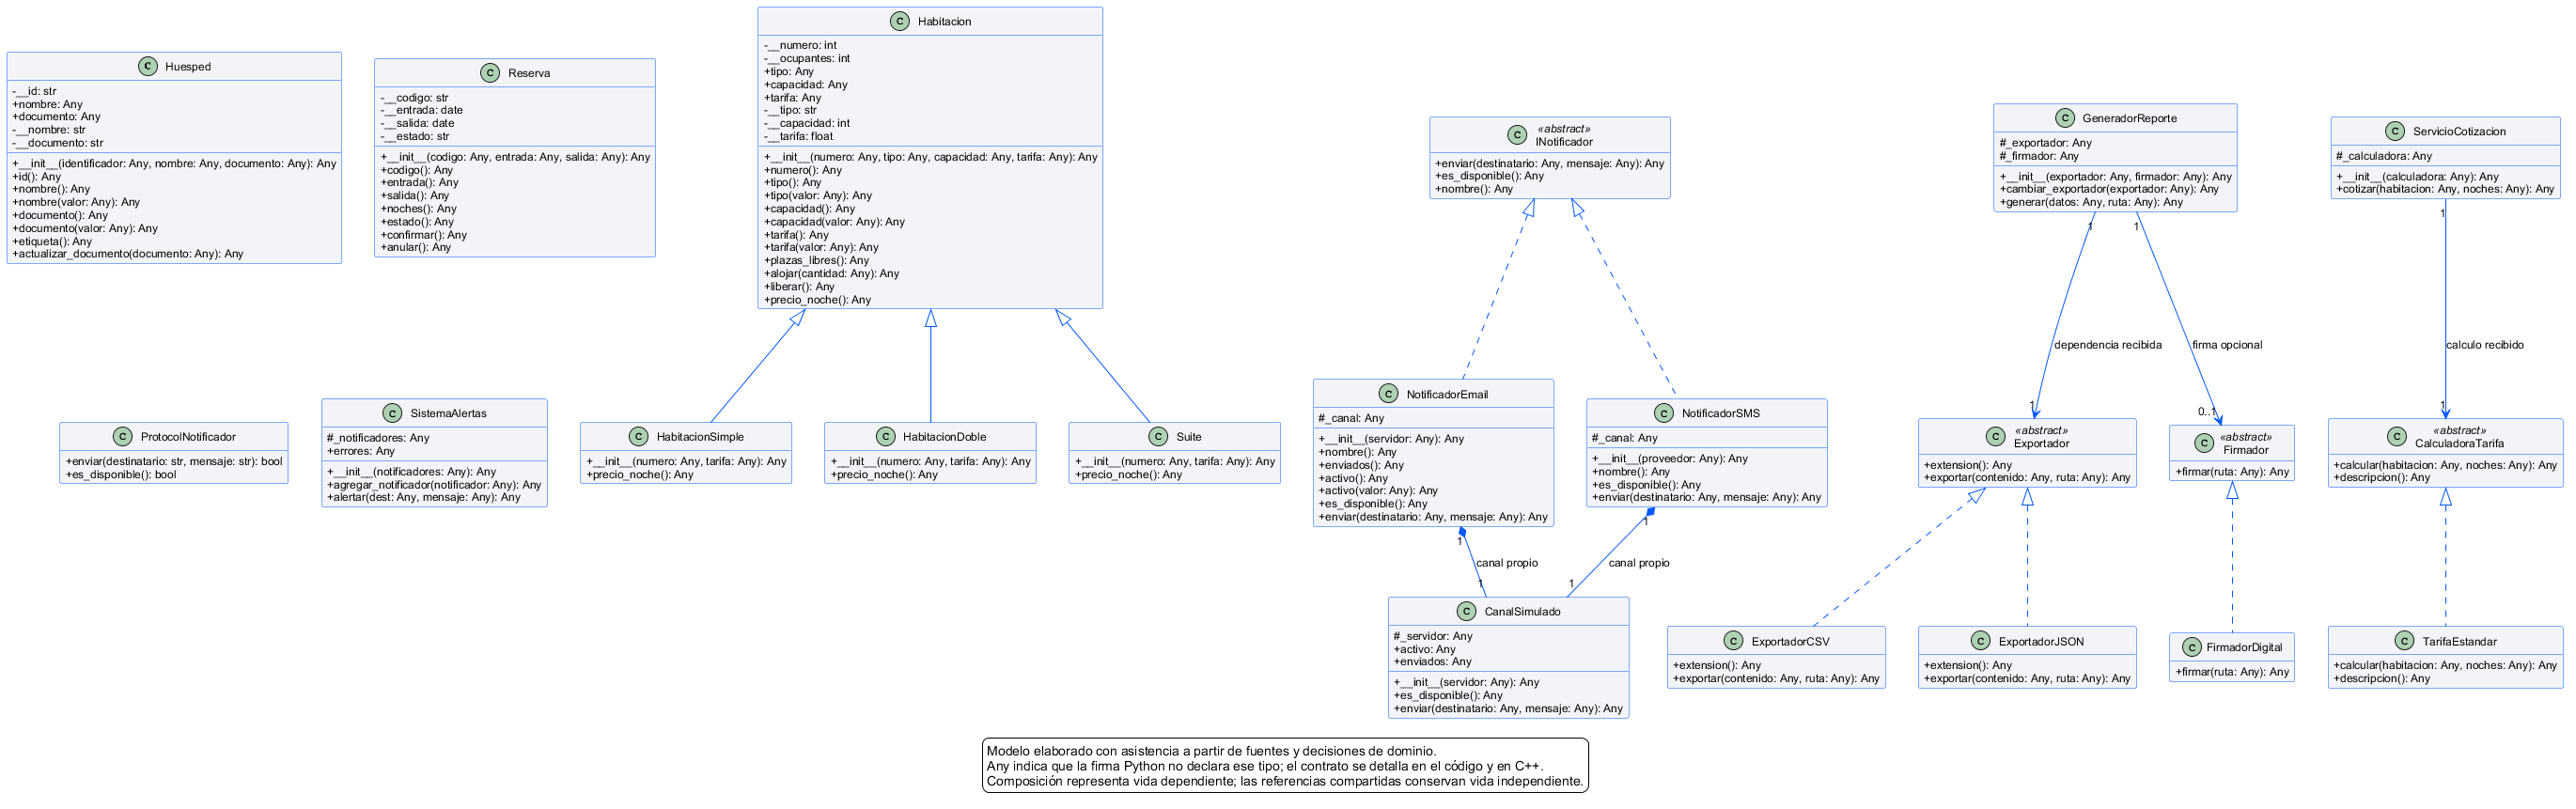

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## resumen informe

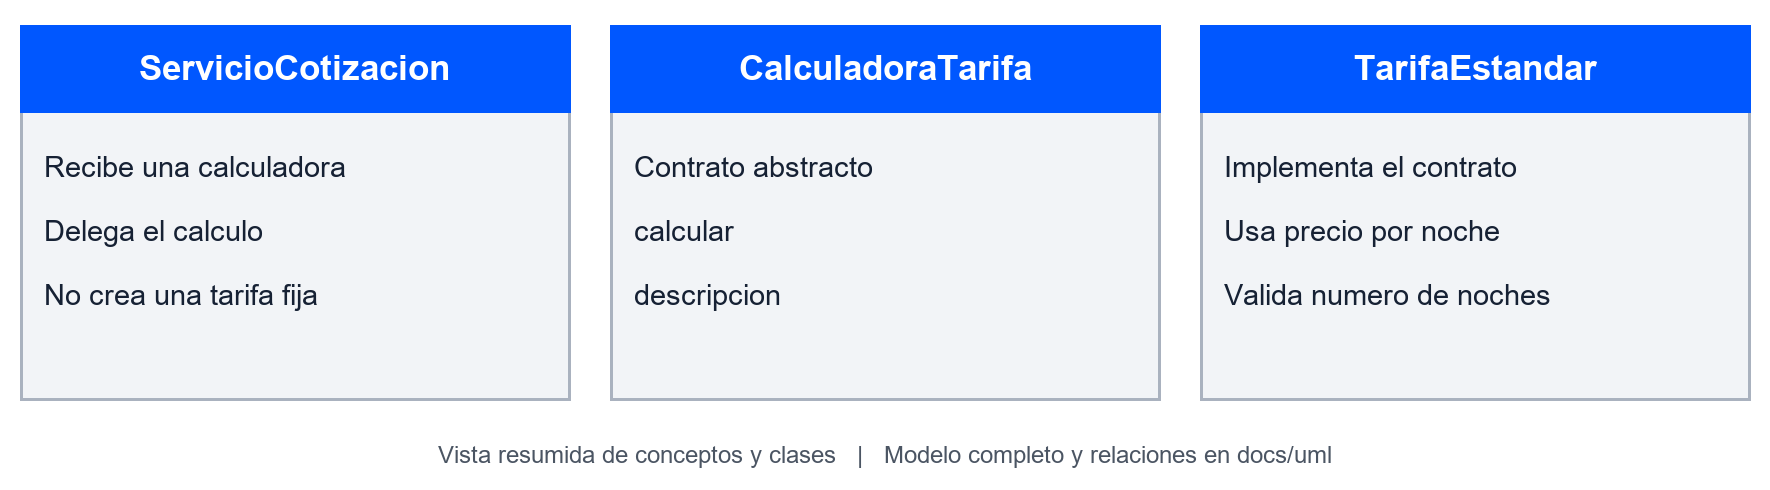

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))
